<a href="https://colab.research.google.com/github/nomulayogambika/EDAV-Project/blob/main/Bus_Route_Passenger_Demand_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files
import pandas as pd

uploaded = files.upload()


Saving Dataset_D_Chennai_Hub_combined_data (1) to Dataset_D_Chennai_Hub_combined_data (1)


In [3]:

import pandas as pd
from google.colab import files


uploaded = files.upload()


filename = next(iter(uploaded))
df = pd.read_csv(filename)


print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Saving Dataset_D_Chennai_Hub_combined_data (1) to Dataset_D_Chennai_Hub_combined_data (1) (1)
Dataset loaded successfully!
Rows and columns: (49, 4)

Column names:
['serial', 'final_booked_seats', 'MONTH(TRAVEL_DATE)', 'YEAR(TRAVEL_DATE)']

First 5 rows:


,serial,final_booked_seats,MONTH(TRAVEL_DATE),YEAR(TRAVEL_DATE)
0,1,10748,1,2011
1,2,8890,2,2011
2,3,8838,3,2011
3,4,13693,4,2011
4,5,20776,5,2011


In [4]:


print("Dataset size:", df.shape)


print("\nDataset information:")
df.info()


print("\nMissing values in each column:")
print(df.isnull().sum())


print("\nNumber of duplicate rows:", df.duplicated().sum())


print("\nBasic statistics:")
display(df.describe(include="all"))


Dataset size: (49, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   serial              49 non-null     int64
 1   final_booked_seats  49 non-null     int64
 2   MONTH(TRAVEL_DATE)  49 non-null     int64
 3   YEAR(TRAVEL_DATE)   49 non-null     int64
dtypes: int64(4)
memory usage: 1.7 KB

Missing values in each column:
serial                0
final_booked_seats    0
MONTH(TRAVEL_DATE)    0
YEAR(TRAVEL_DATE)     0
dtype: int64

Number of duplicate rows: 0

Basic statistics:


,serial,final_booked_seats,MONTH(TRAVEL_DATE),YEAR(TRAVEL_DATE)
count,49.00000,49.000000,49.000000,49.000000
mean,25.00000,28072.510204,6.387755,2012.551020
std,14.28869,12910.577222,3.540341,1.173691
min,1.00000,8838.000000,1.000000,2011.000000
25%,13.00000,20439.000000,3.000000,2012.000000
50%,25.00000,24915.000000,6.000000,2013.000000
75%,37.00000,31372.000000,9.000000,2014.000000
max,49.00000,75524.000000,12.000000,2015.000000


First date: 2011-01-01
Last date: 2015-01-01


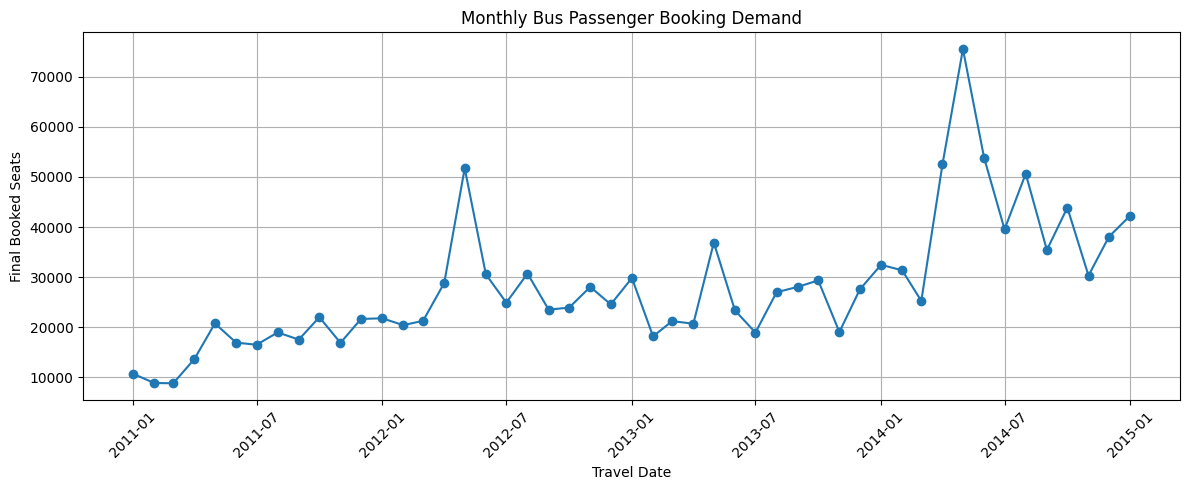

In [5]:

import pandas as pd
import matplotlib.pyplot as plt


df["travel_date"] = pd.to_datetime({
    "year": df["YEAR(TRAVEL_DATE)"],
    "month": df["MONTH(TRAVEL_DATE)"],
    "day": 1
})


df = df.sort_values("travel_date")


print("First date:", df["travel_date"].min().date())
print("Last date:", df["travel_date"].max().date())


plt.figure(figsize=(12, 5))
plt.plot(
    df["travel_date"],
    df["final_booked_seats"],
    marker="o"
)

plt.title("Monthly Bus Passenger Booking Demand")
plt.xlabel("Travel Date")
plt.ylabel("Final Booked Seats")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


,Number of Records,Average Booked Seats,Total Booked Seats,Minimum Booked Seats,Maximum Booked Seats
YEAR(TRAVEL_DATE),,,,,
2011,12,16130.83,193570,8838,22030
2012,12,27537.92,330455,20439,51739
2013,12,25026.00,300312,18201,36909
2014,12,42412.17,508946,25275,75524
2015,1,42270.00,42270,42270,42270


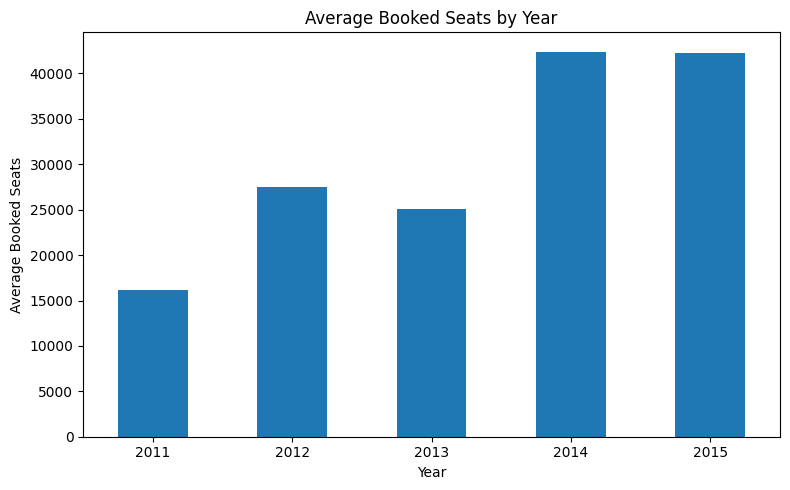

In [6]:


yearly_summary = df.groupby("YEAR(TRAVEL_DATE)")["final_booked_seats"].agg(
    ["count", "mean", "sum", "min", "max"]
).round(2)

yearly_summary.columns = [
    "Number of Records",
    "Average Booked Seats",
    "Total Booked Seats",
    "Minimum Booked Seats",
    "Maximum Booked Seats"
]

display(yearly_summary)


yearly_summary["Average Booked Seats"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Booked Seats by Year"
)

plt.xlabel("Year")
plt.ylabel("Average Booked Seats")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Monthly booking summary:


,Average Booked Seats,Number of Records
MONTH(TRAVEL_DATE),,
1,27428.80,5
2,19725.50,4
3,19162.25,4
4,28939.50,4
5,46237.00,4
6,31188.75,4
7,24987.00,4
8,31843.75,4
9,26145.25,4


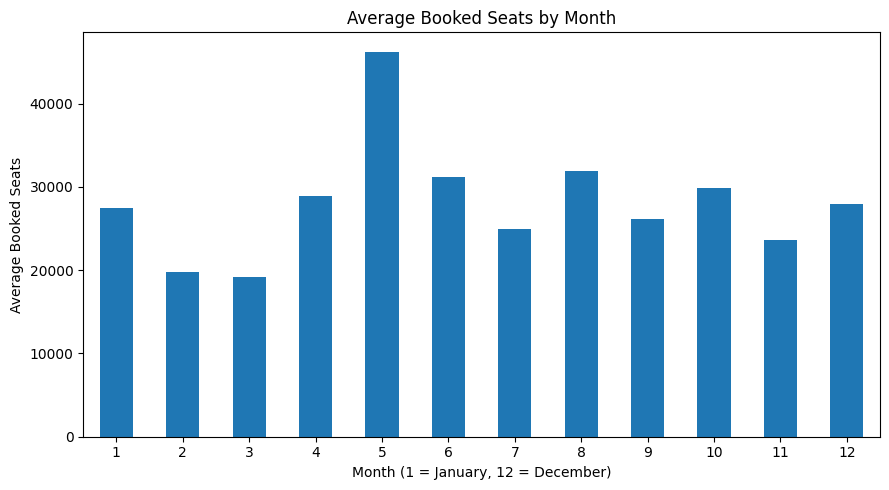

In [7]:


monthly_summary = df.groupby("MONTH(TRAVEL_DATE)")[
    "final_booked_seats"
].agg(["mean", "count"]).round(2)

monthly_summary.columns = [
    "Average Booked Seats",
    "Number of Records"
]

print("Monthly booking summary:")
display(monthly_summary)


monthly_summary["Average Booked Seats"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Booked Seats by Month"
)

plt.xlabel("Month (1 = January, 12 = December)")
plt.ylabel("Average Booked Seats")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [8]:


highest = df.loc[df["final_booked_seats"].idxmax()]


lowest = df.loc[df["final_booked_seats"].idxmin()]

print("HIGHEST BOOKED-SEAT RECORD")
print("Year:", int(highest["YEAR(TRAVEL_DATE)"]))
print("Month:", int(highest["MONTH(TRAVEL_DATE)"]))
print("Booked seats:", int(highest["final_booked_seats"]))

print("\nLOWEST BOOKED-SEAT RECORD")
print("Year:", int(lowest["YEAR(TRAVEL_DATE)"]))
print("Month:", int(lowest["MONTH(TRAVEL_DATE)"]))
print("Booked seats:", int(lowest["final_booked_seats"]))

# Show the five highest records
print("\nTOP 5 BOOKED-SEAT RECORDS")
display(
    df.nlargest(5, "final_booked_seats")[
        ["YEAR(TRAVEL_DATE)", "MONTH(TRAVEL_DATE)",
         "final_booked_seats"]
    ]
)


HIGHEST BOOKED-SEAT RECORD
Year: 2014
Month: 5
Booked seats: 75524

LOWEST BOOKED-SEAT RECORD
Year: 2011
Month: 3
Booked seats: 8838

TOP 5 BOOKED-SEAT RECORDS


,YEAR(TRAVEL_DATE),MONTH(TRAVEL_DATE),final_booked_seats
40,2014,5,75524
41,2014,6,53847
39,2014,4,52502
16,2012,5,51739
43,2014,8,50650


In [9]:


monthly_counts = df.groupby(
    ["YEAR(TRAVEL_DATE)", "MONTH(TRAVEL_DATE)"]
).size()


expected_months = pd.period_range(
    start="2011-01",
    end="2015-01",
    freq="M"
)


observed_months = pd.PeriodIndex(
    df["YEAR(TRAVEL_DATE)"].astype(str)
    + "-"
    + df["MONTH(TRAVEL_DATE)"].astype(str).str.zfill(2),
    freq="M"
)

missing_months = expected_months.difference(observed_months.unique())

print("Expected months:", len(expected_months))
print("Months represented:", observed_months.nunique())
print("Missing months:", len(missing_months))

if len(missing_months) > 0:
    print("Missing month(s):", list(missing_months))
else:
    print("Every month in the period is represented.")


Expected months: 49
Months represented: 49
Missing months: 0
Every month in the period is represented.


In [10]:

research_questions = [
    "How did booked-seat figures change over time?",
    "Which year had the highest average booked-seat figure?",
    "Which month had the highest and lowest average booked-seat figures?",
    "What were the highest and lowest individual booked-seat records?",
    "What recommendations can be made from the observed booking patterns?"
]

for i, question in enumerate(research_questions, start=1):
    print(f"{i}. {question}")


1. How did booked-seat figures change over time?
2. Which year had the highest average booked-seat figure?
3. Which month had the highest and lowest average booked-seat figures?
4. What were the highest and lowest individual booked-seat records?
5. What recommendations can be made from the observed booking patterns?
